## Setup — import libraries and find the shared data folder

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the shared data folder from the repository root or app/L8.
def data_path(filename):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        file = folder / "data" / filename
        if file.is_file():
            return file
    raise FileNotFoundError(f"Cannot find {filename} from {Path.cwd()}")

## 1. Load the observations

`sunspots` is the historical annual activity measure. We will improve the presentation of the same data step by step.

In [2]:
df = pd.read_csv(data_path("sunspots.csv"))
display(df.head())
print("Years:", df["year"].min(), "to", df["year"].max())

,year,sunspots
0,1700,5.0
1,1701,11.0
2,1702,16.0
3,1703,23.0
4,1704,36.0


Years: 1700 to 2008


## 2. A basic plot — what is missing?

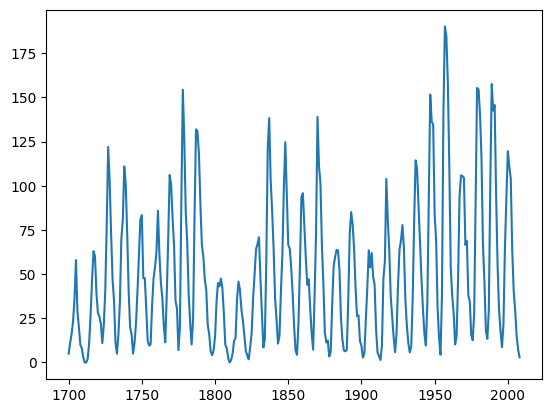

In [3]:
plt.plot(df["year"], df["sunspots"])
plt.show()

## 3. Add the title, axis labels, grid and line colour

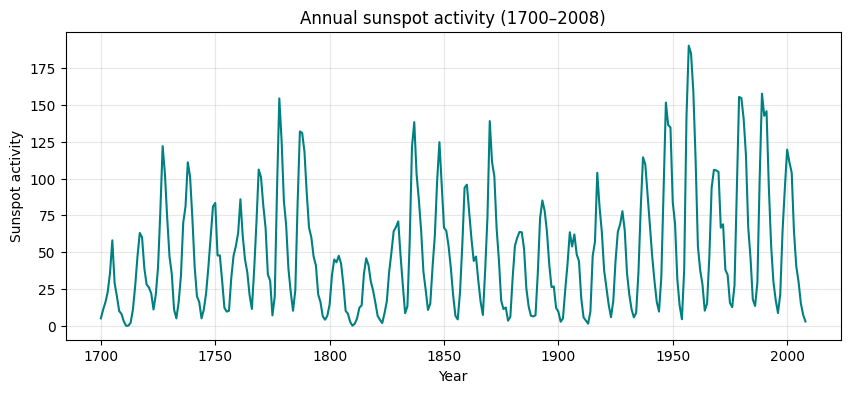

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(df["year"], df["sunspots"], color="teal")
plt.title("Annual sunspot activity (1700–2008)")
plt.xlabel("Year")
plt.ylabel("Sunspot activity")
plt.grid(alpha=0.3)
plt.show()

## 4. Add a rolling average

An 11-year rolling average makes longer patterns easier to see. It smooths observations; it is **not a forecast**.

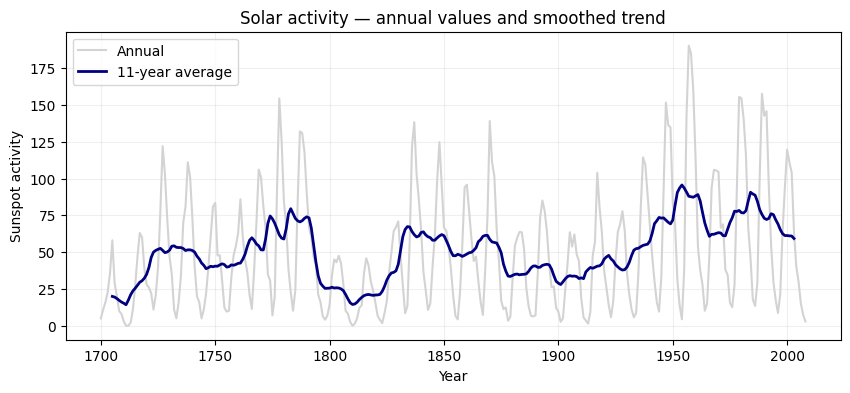

In [5]:
df["smooth"] = df["sunspots"].rolling(11, center=True).mean()
plt.figure(figsize=(10, 4))
plt.plot(df["year"], df["sunspots"], color="lightgray", label="Annual")
plt.plot(df["year"], df["smooth"], color="navy", linewidth=2, label="11-year average")
plt.title("Solar activity — annual values and smoothed trend")
plt.xlabel("Year")
plt.ylabel("Sunspot activity")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 5. Annotate the highest observed year

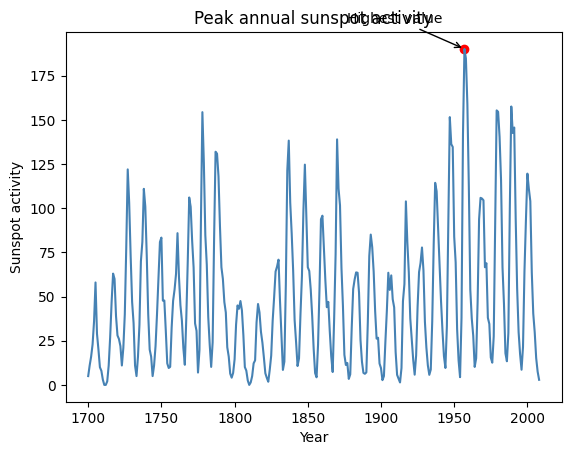

In [6]:
peak = df.loc[df["sunspots"].idxmax()]
plt.plot(df["year"], df["sunspots"], color="steelblue")
plt.scatter(peak["year"], peak["sunspots"], color="red")
plt.annotate("Highest value", (peak["year"], peak["sunspots"]),
             xytext=(peak["year"] - 80, peak["sunspots"] + 15),
             arrowprops={"arrowstyle": "->"})
plt.title("Peak annual sunspot activity")
plt.xlabel("Year")
plt.ylabel("Sunspot activity")
plt.show()

## 6. Two subplots — full history and recent years

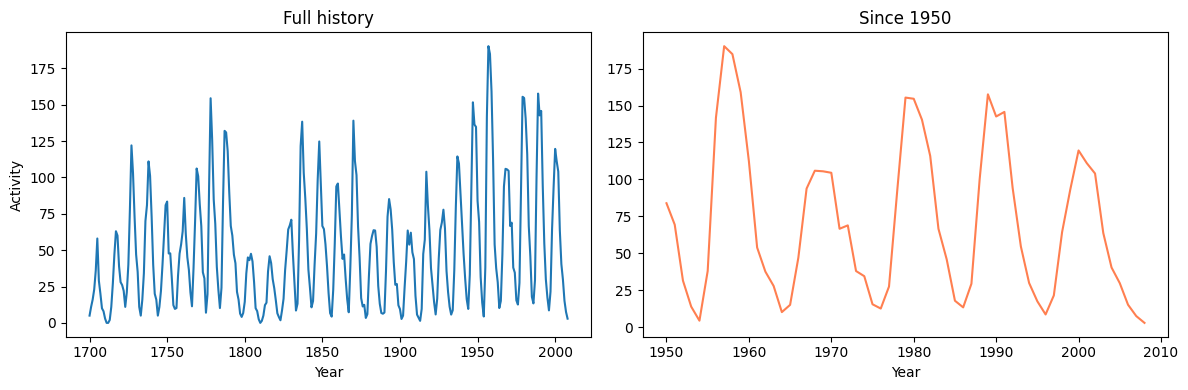

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(df["year"], df["sunspots"])
axes[0].set_title("Full history")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Activity")
recent = df[df["year"] >= 1950]
axes[1].plot(recent["year"], recent["sunspots"], color="coral")
axes[1].set_title("Since 1950")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

### Discuss

What does the rolling average hide? Why are clear axis labels and a legend more useful than decoration?

## Your turn — short challenges

1. Change the rolling average from **11 years** to **5 years**.
2. Add a dashed line style to the smoothed series.
3. Explain one benefit and one limitation of smoothing.

In [8]:
# Write your solution here.
# Start by changing one line from an example above.